# Informed search

**Group E01** — Project 01, Artificial Intelligence 2026-27. Supporting notebook of the main one.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # so Python finds the 'src' folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.model import Problem, State, Stop
from src import informed, local_search, csp

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

prob = Problem.from_csv("../data_tiny")          # development dataset
prob_small = Problem.from_csv("../data_small")   # larger dataset, used to check that the code scales

In [2]:
# Greedy and A* (h1, h2) on both datasets. Needed by the local search and the comparison.
df_inf, states_inf, plans_inf = informed.run_all(prob)
df_inf_small, states_inf_small, plans_inf_small = informed.run_all(prob_small)

# 4. Problem Solving

## 4.1 Informed search: Greedy best-first and A*

**Goal.** Build the visiting order of every vehicle trip with informed search and compare Greedy best-first with A* using two heuristics, counting the expanded nodes.

**Problem formulation (one trip of one vehicle).** Every route is split into *legs* that start and end at the collection center: a *collection leg* (center > producers > center) and a *delivery leg* (center > customers > center).

| Element | Definition |
|---|---|
| State | `(current location, set of stops still to visit)` and the clock (kept in the node) |
| Initial state | At the center, all stops pending |
| Actions | Go to one of the pending stops (wait if the window is not open yet) |
| Transition | Move, update clock (travel + wait + service), remove the stop from the pending set |
| Goal test | No pending stops and the vehicle is back at the center |
| Step cost | Distance in km of the move |
| Pruning | A branch is discarded if the window of a stop has already closed |

**Heuristics** (remaining cost to visit the pending stops and return to the center):

* `h1` = distance to the *nearest* pending stop (or to the center if none is left).
* `h2` = for every pending stop, the cheapest incoming edge, plus the cheapest edge back to the center; summed.

Both are **admissible**: every pending stop must be entered by some edge, which costs at least its cheapest incoming edge, and `h1` is at most one of those terms. They never overestimate, so A* returns the optimal order of a leg. Greedy uses only `f = h`, A* uses `f = g + h`. We do not prove consistency. To avoid re-expanding states, the search keeps, for every state, the best (cost, time) found so far and discards a node that is not better in both.

In [3]:
df_inf

,algorithm,heuristic,cost_km,expanded_nodes,generated_nodes,seconds,status,feasible
0,greedy,h1,724.28,46,54,0.0006,solved,True
1,greedy,h2,744.59,30,39,0.0005,solved,True
2,astar,h1,724.28,49,57,0.0006,solved,True
3,astar,h2,724.28,40,52,0.0006,solved,True


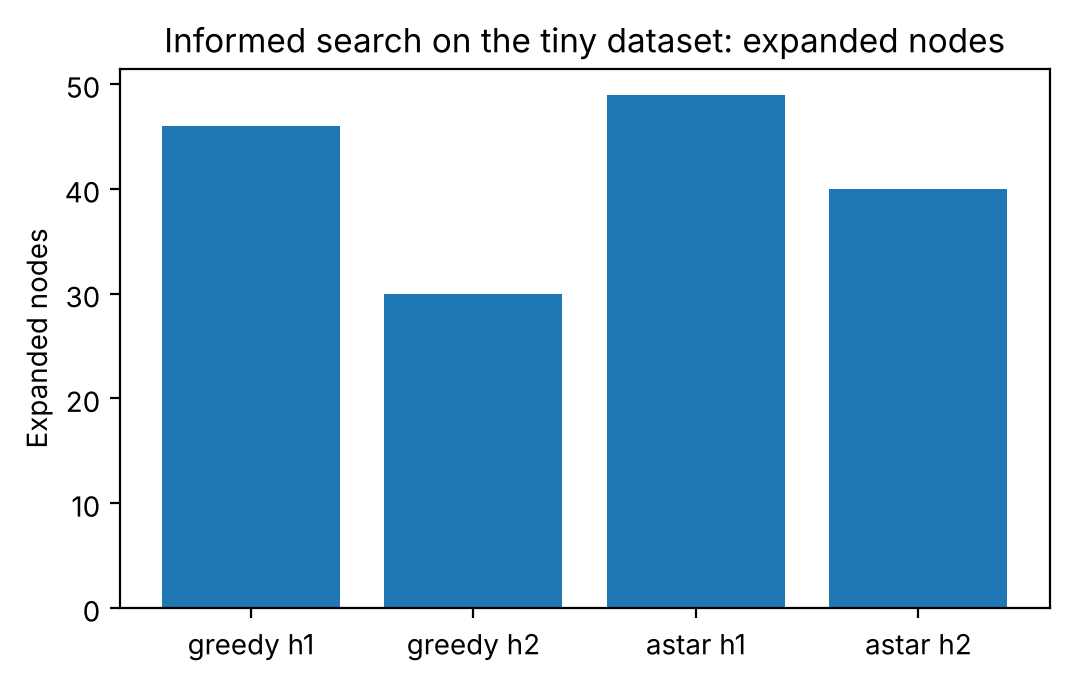

In [4]:
# Expanded nodes of each algorithm (tiny dataset)
labels = df_inf.algorithm + " " + df_inf.heuristic
plt.figure(figsize=(6, 3.5))
plt.bar(labels, df_inf.expanded_nodes, color="tab:blue")
plt.ylabel("Expanded nodes")
plt.title("Informed search on the tiny dataset: expanded nodes")
plt.show()

**Check: is the order found by A* optimal?** For every list of stops of the A* plan we try all the orderings (`itertools.permutations`) with the other lists fixed and keep the cheapest feasible one.

In [5]:
import copy, itertools

plan = plans_inf[("astar", "h2")]
plan_cost, _ = local_search.evaluate(prob, plan)
rows = []
for day in plan:
    for kind in ("collect", "deliver"):
        for vid, stops in plan[day][kind].items():
            if len(stops) < 2:
                continue
            best = None
            for order in itertools.permutations(stops):
                test = copy.deepcopy(plan)
                test[day][kind][vid] = list(order)
                cost, ok = local_search.evaluate(prob, test)
                if ok and (best is None or cost < best):
                    best = cost
            rows.append({"day": str(day), "list": kind, "vehicle": vid, "stops": len(stops),
                         "A* plan (km)": round(plan_cost, 2), "best ordering (km)": round(best, 2)})
brute = pd.DataFrame(rows)
print("Any ordering cheaper than the A* plan:", (brute["best ordering (km)"] < brute["A* plan (km)"] - 1e-6).any())
brute

Any ordering cheaper than the A* plan: False


,day,list,vehicle,stops,A* plan (km),best ordering (km)
0,2026-10-30,collect,2,2,724.28,724.28
1,2026-10-30,deliver,1,2,724.28,724.28
2,2026-10-30,deliver,2,2,724.28,724.28
3,2026-10-31,collect,2,3,724.28,724.28
4,2026-10-31,deliver,1,5,724.28,724.28
5,2026-10-31,deliver,2,3,724.28,724.28


In [6]:
# Schedule found by A* with h2 (tiny)
prob.route_table(states_inf[("astar", "h2")])

,vehicle,stop,action,location,arrival,service_start,window,items
0,1,1,pickup,3,30 00:38,30 08:00,30 08:00 - 30 09:45,"[6, 11, 22, 24, 26, 29, 35]"
1,1,2,unload,4,30 08:48,30 08:48,,"[6, 11, 22, 24, 26, 29, 35]"
2,2,1,pickup,1,30 00:40,30 09:30,30 09:30 - 30 09:45,"[5, 13, 25, 31, 32, 34, 37, 40]"
3,2,2,pickup,2,30 10:11,30 10:11,30 09:00 - 30 10:30,"[12, 23, 27, 28, 30, 33, 36, 38, 39]"
4,2,3,unload,4,30 11:11,30 11:11,,"[5, 13, 25, 31, 32, 34, 37, 40, 12, 23, 27, 28..."
5,1,3,load,4,30 09:03,30 11:26,,"[36, 37, 38, 39, 40, 32, 33, 34, 35]"
6,1,4,deliver,6,30 12:29,30 12:29,30 12:15 - 30 14:45,"[36, 37, 38, 39, 40]"
7,1,5,deliver,5,30 13:51,30 13:51,30 10:15 - 30 14:00,"[32, 33, 34, 35]"
8,1,6,return,4,30 14:26,30 14:26,,[]
9,2,4,load,4,30 11:26,30 11:26,,"[30, 31, 11, 12, 13]"


In [7]:
# The same algorithms on the small dataset
df_inf_small

,algorithm,heuristic,cost_km,expanded_nodes,generated_nodes,seconds,status,feasible
0,greedy,h1,1090.63,762,1489,0.0065,solved,True
1,greedy,h2,1131.96,149,218,0.0015,solved,True
2,astar,h1,1031.75,590,1346,0.0058,solved,True
3,astar,h2,1031.75,453,1233,0.0042,solved,True


### Observations (executed results)

* **Tiny.** Greedy h1, A* h1 and A* h2 all return **724.28 km**. The brute-force check above finds no cheaper ordering of any list, so these routes are optimal *for the vehicle split used*. Greedy h2 returns 744.59 km (+2.8 %).
* **Expanded nodes (tiny).** Greedy h1 46, Greedy h2 30, A* h1 49, A* h2 40. `h2` is better informed than `h1`: A* expands 18 % fewer nodes with it (40 vs 49).
* **Small.** A* finds 1031.75 km with both heuristics against 1090.63 km for Greedy h1 (-5.4 %). Expanded nodes: Greedy h1 762, A* h1 590, A* h2 453 (-23 % against h1), Greedy h2 149.
* Greedy with `h2` is the cheapest to run but gives the worst routes: with `f = h` it ignores the distance already travelled. A* pays more nodes and returns better routes, as expected.
* **Limits.** The legs of the tiny dataset have at most 5 stops, so the differences are small and all times are below a millisecond. The split of the items between the vehicles is decided *before* the search (first fit with random restarts, fixed seed) and is not optimised here; this is why local search improves the solutions so much later.